In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [4]:
df = pd.read_csv("Unemployment in India.csv")
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [7]:
print("Shape:", df.shape)

print("\nColumn names (note the extra spaces):")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nNull values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (768, 7)

Column names (note the extra spaces):
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Data types:
Region                                       object
 Date                                        object
 Frequency                                   object
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                         object
dtype: object

Null values per column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Duplicate rows: 27


In [9]:
# Remove extra spaces from column names and give them shorter names
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate",
    "Region.1": "Zone"
})

# Drop empty rows and duplicates
rows_before = df.shape[0]
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"Rows before cleaning: {rows_before} | after cleaning: {df.shape[0]}")

# Type conversion: strip spaces in text columns and convert Date to datetime
df["Region"] = df["Region"].str.strip()
df["Frequency"] = df["Frequency"].str.strip()
df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(), dayfirst=True)

# Extract month and year for time-based analysis
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Year"] = df["Date"].dt.year

print("\nNull values after cleaning:")
print(df.isnull().sum())

print("\nData types after conversion:")
print(df.dtypes)

Rows before cleaning: 768 | after cleaning: 740

Null values after cleaning:
Region                       0
Date                         0
Frequency                    0
Unemployment_Rate            0
Employed                     0
Labour_Participation_Rate    0
Area                         0
Month                        0
Month_Name                   0
Year                         0
dtype: int64

Data types after conversion:
Region                               object
Date                         datetime64[ns]
Frequency                            object
Unemployment_Rate                   float64
Employed                            float64
Labour_Participation_Rate           float64
Area                                 object
Month                                 int32
Month_Name                           object
Year                                  int32
dtype: object


In [11]:
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Number of regions:", df["Region"].nunique())

df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].describe()

Date range: 2019-05-31 to 2020-06-30
Number of regions: 28


,Unemployment_Rate,Employed,Labour_Participation_Rate
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [13]:
# Average unemployment rate for each state, highest first
region_avg = (
    df.groupby("Region")["Unemployment_Rate"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("Average unemployment rate by region (%):")
print(region_avg)

Average unemployment rate by region (%):
Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Punjab              12.03
Puducherry          10.22
Kerala              10.12
Tamil Nadu           9.28
Goa                  9.27
Chhattisgarh         9.24
West Bengal          8.12
Telangana            7.74
Maharashtra          7.56
Andhra Pradesh       7.48
Madhya Pradesh       7.41
Sikkim               7.25
Karnataka            6.68
Gujarat              6.66
Uttarakhand          6.58
Assam                6.43
Odisha               5.66
Meghalaya            4.80
Name: Unemployment_Rate, dtype: float64


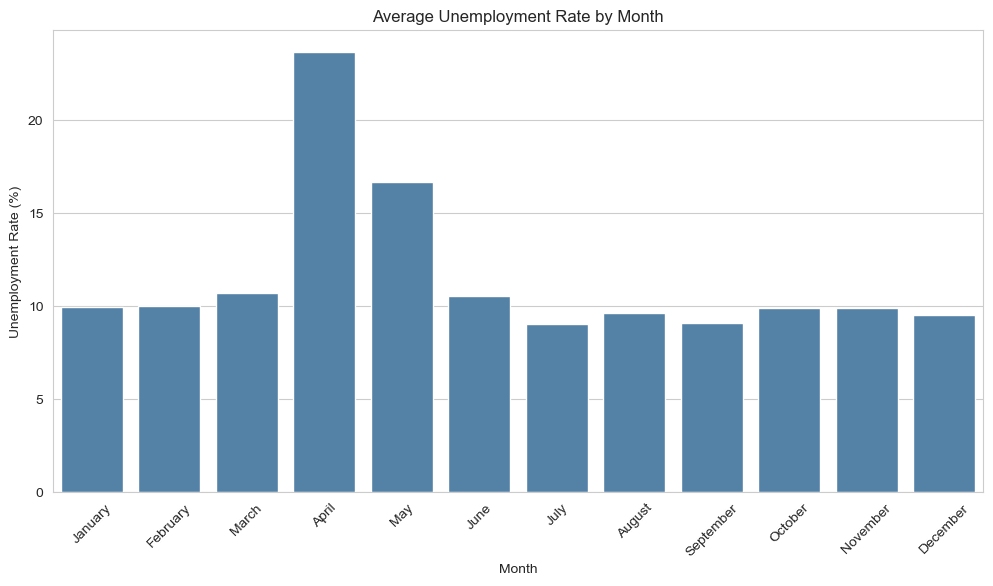

In [17]:
# Average unemployment rate for each calendar month, in calendar order
month_avg = df.groupby(["Month", "Month_Name"])["Unemployment_Rate"].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=month_avg, x="Month_Name", y="Unemployment_Rate", color="steelblue")
plt.title("Average Unemployment Rate by Month")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [19]:
# Confirm the columns needed below exist
required = ["Region", "Date", "Unemployment_Rate", "Employed", "Labour_Participation_Rate"]
print("Missing columns:", [c for c in required if c not in df.columns])
df[required].head(3)

Missing columns: []


,Region,Date,Unemployment_Rate,Employed,Labour_Participation_Rate
0,Andhra Pradesh,2019-05-31,3.65,11999139.0,43.24
1,Andhra Pradesh,2019-06-30,3.05,11755881.0,42.05
2,Andhra Pradesh,2019-07-31,3.75,12086707.0,43.50


States plotted: ['Delhi', 'Maharashtra', 'Tamil Nadu', 'Karnataka', 'Kerala']


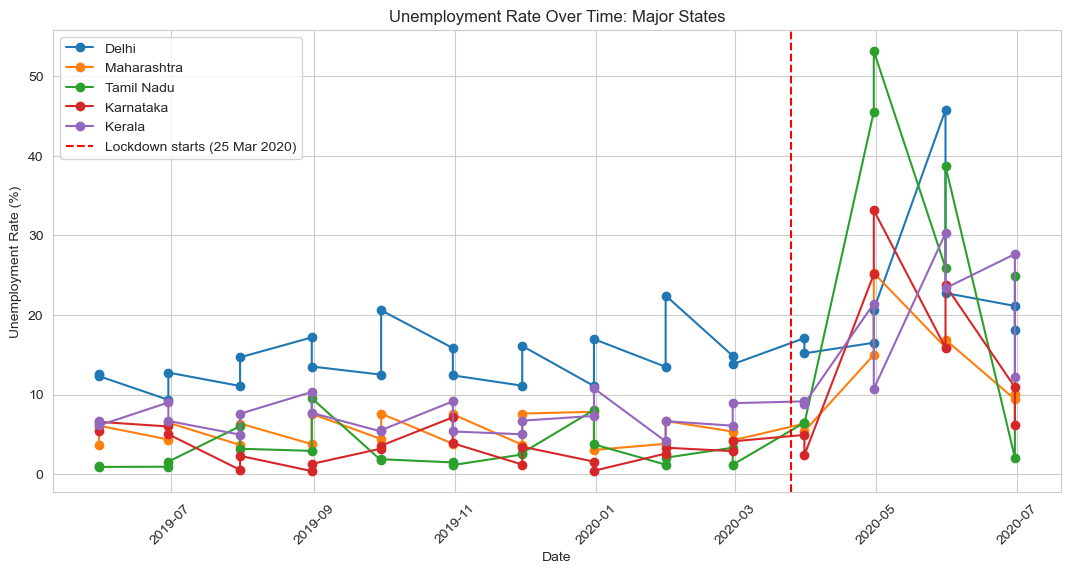

In [21]:
# Choose major states (only those present in the dataset are used)
states = ["Delhi", "Maharashtra", "Tamil Nadu", "Karnataka", "Kerala"]
states = [s for s in states if s in df["Region"].unique()]
print("States plotted:", states)

plt.figure(figsize=(13, 6))
for state in states:
    state_df = df[df["Region"] == state].sort_values("Date")
    plt.plot(state_df["Date"], state_df["Unemployment_Rate"], marker="o", label=state)

# Mark the start of the national COVID-19 lockdown
plt.axvline(pd.Timestamp("2020-03-25"), color="red", linestyle="--", label="Lockdown starts (25 Mar 2020)")

plt.title("Unemployment Rate Over Time: Major States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.show()

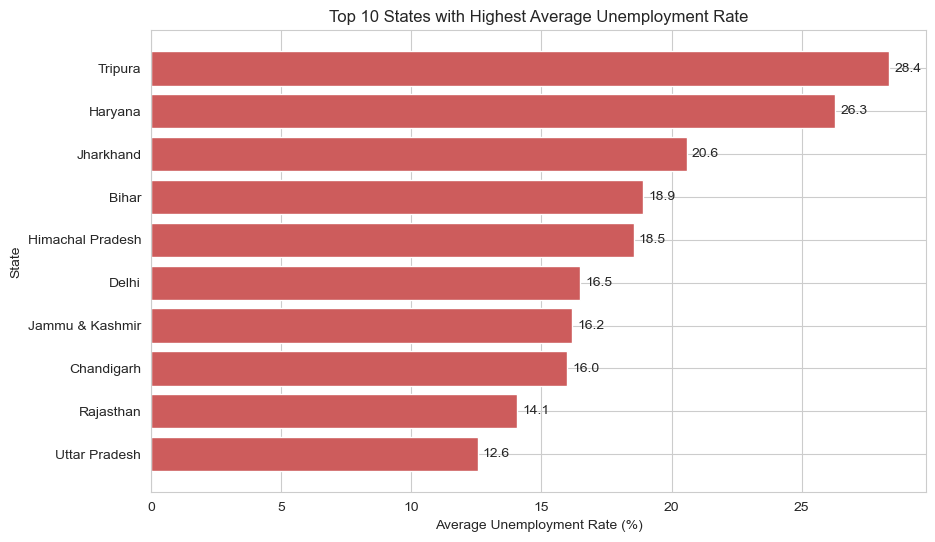

In [23]:
# Average unemployment rate per state, keep the top 10
top10 = (
    df.groupby("Region")["Unemployment_Rate"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(top10.index, top10.values, color="indianred")
plt.title("Top 10 States with Highest Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State")

# Show value labels on the bars
for i, v in enumerate(top10.values):
    plt.text(v + 0.2, i, f"{v:.1f}", va="center")
plt.show()

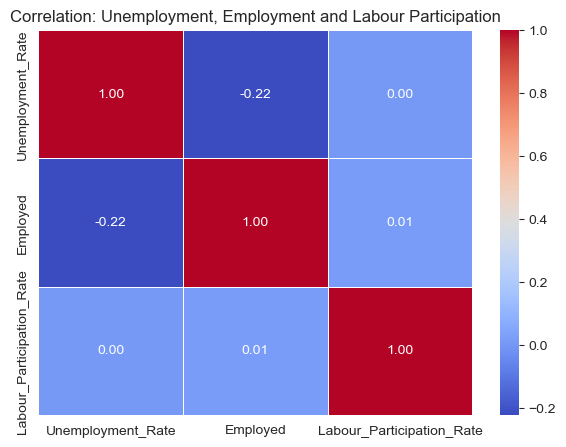

In [25]:
corr = df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation: Unemployment, Employment and Labour Participation")
plt.show()

In [27]:
# India's nationwide lockdown began on 25 March 2020
cutoff = pd.Timestamp("2020-03-25")

pre_covid = df[df["Date"] < cutoff]
post_covid = df[df["Date"] >= cutoff]

columns = ["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]
comparison = pd.DataFrame({
    "Pre-COVID": pre_covid[columns].mean(),
    "Post-COVID": post_covid[columns].mean()
}).round(2)

print(f"Pre-COVID records: {len(pre_covid)} | Post-COVID records: {len(post_covid)}\n")
comparison

Pre-COVID records: 536 | Post-COVID records: 204



,Pre-COVID,Post-COVID
Unemployment_Rate,9.51,17.77
Employed,7466027.87,6517203.34
Labour_Participation_Rate,43.89,39.33


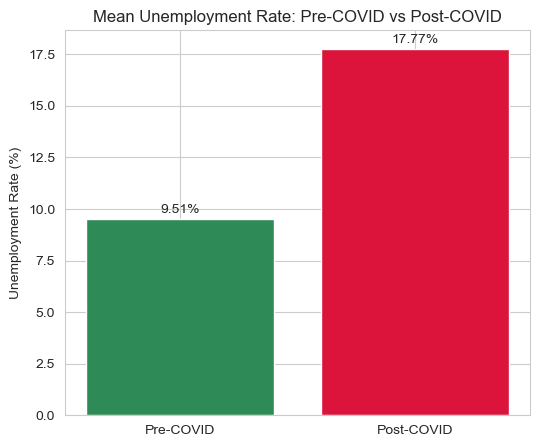

Unemployment rate increased by 86.9% after COVID-19 began.


In [29]:
means = [pre_covid["Unemployment_Rate"].mean(), post_covid["Unemployment_Rate"].mean()]

plt.figure(figsize=(6, 5))
plt.bar(["Pre-COVID", "Post-COVID"], means, color=["seagreen", "crimson"])
plt.title("Mean Unemployment Rate: Pre-COVID vs Post-COVID")
plt.ylabel("Unemployment Rate (%)")
for i, v in enumerate(means):
    plt.text(i, v + 0.3, f"{v:.2f}%", ha="center")
plt.show()

change = ((means[1] - means[0]) / means[0]) * 100
print(f"Unemployment rate increased by {change:.1f}% after COVID-19 began.")

In [31]:
# Compare each state's average before and after the lockdown
state_impact = pd.DataFrame({
    "Pre": pre_covid.groupby("Region")["Unemployment_Rate"].mean(),
    "Post": post_covid.groupby("Region")["Unemployment_Rate"].mean()
})
state_impact["Increase"] = (state_impact["Post"] - state_impact["Pre"]).round(2)

print("Top 5 most affected states (increase in percentage points):")
state_impact.sort_values("Increase", ascending=False).head(5).round(2)

Top 5 most affected states (increase in percentage points):


,Pre,Post,Increase
Region,,,
Puducherry,1.59,38.96,37.36
Tamil Nadu,2.84,25.40,22.57
Jharkhand,14.28,36.35,22.07
Bihar,13.83,31.63,17.80
Karnataka,3.23,15.28,12.05
